# 224166P - Ruwanima K.P.
# Ensemble Learning Dashboard: Bagging, Boosting, Stacking and Hybrid Models

**Module:** Machine Learning and Pattern Recognition  
**Context:** Sri Lankan used-vehicle price prediction using a local vehicle listing dataset (`car_price_dataset.csv`).

> **AI-use declaration:** The code structure, the dashboard front end, and the draft explanations in this notebook were generated with the help of AI tools (ChatGPT by OpenAI and GitHub Copilot in VS Code). I reviewed, ran, and adapted them, while the dataset choice, experiment settings, and final interpretation of the results are my own.

This notebook compares bagging, boosting, stacking, voting, and an RF+ANN hybrid on a local Sri Lankan used-vehicle dataset. The target is vehicle price in Lakhs (1 Lakh = LKR 100,000).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

root = Path('..')
data = pd.read_csv(root / 'data/processed/cleaned_vehicle_data.csv')
ensemble = pd.read_csv(root / 'artifacts/ensemble_results.csv')
predictions = pd.read_csv(root / 'artifacts/test_predictions.csv')
metadata = json.loads((root / 'artifacts/model_metadata.json').read_text())
print('Clean dataset shape:', data.shape)
display(ensemble)

Clean dataset shape: (9536, 17)


,Model,Training Time (s),CV MAE Lakhs,MAE_Lakhs,RMSE_Lakhs,R2
0,Random Forest,8.155219,5.494608,5.355621,14.983281,0.895814
1,Gradient Boosting,1.093218,8.274732,8.533182,16.795396,0.869089
2,XGBoost,0.302917,6.526421,6.463140,14.286071,0.905285
3,Extra Trees,12.071531,5.303820,5.150332,15.079362,0.894474
4,Voting,11.058700,6.479467,6.604102,15.815118,0.883925
5,Stacking,64.263533,5.799412,5.815366,14.677520,0.900023
6,Random Forest + ANN,80.309053,5.505457,5.596905,14.267820,0.905527
7,LightGBM,0.771517,6.904183,6.550017,13.648461,0.913551
8,CatBoost,5.096745,8.143561,8.462002,16.706047,0.870479


## 1. Data pipeline
The pipeline removes the identifier, validates numerical fields and dates, creates vehicle age, removes invalid rows and near duplicates, imputes missing values, and one-hot encodes categorical fields. The 80/20 train/test split is reproducible with `random_state=42`. A held-out test set is used only for final evaluation.

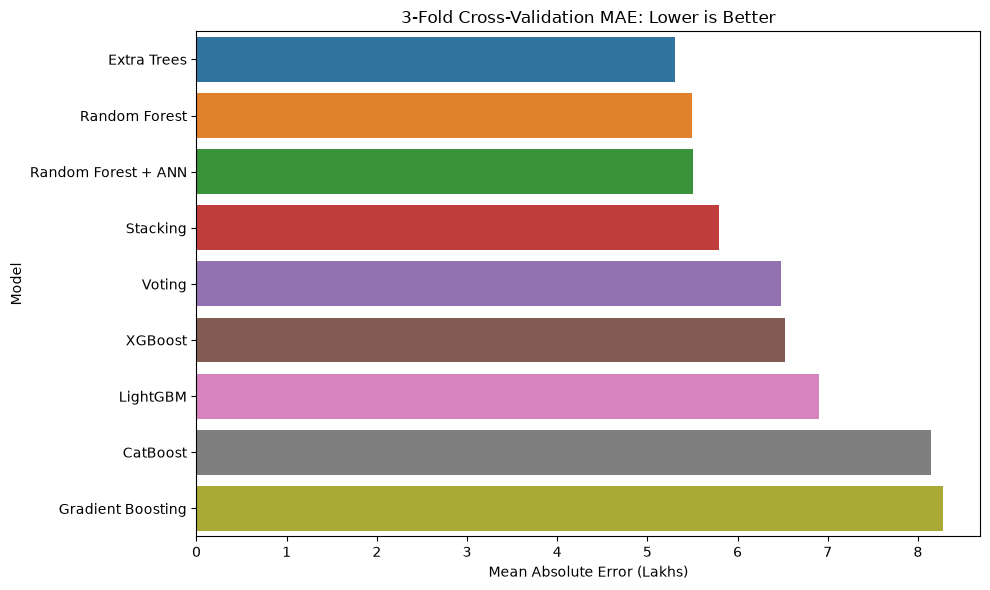

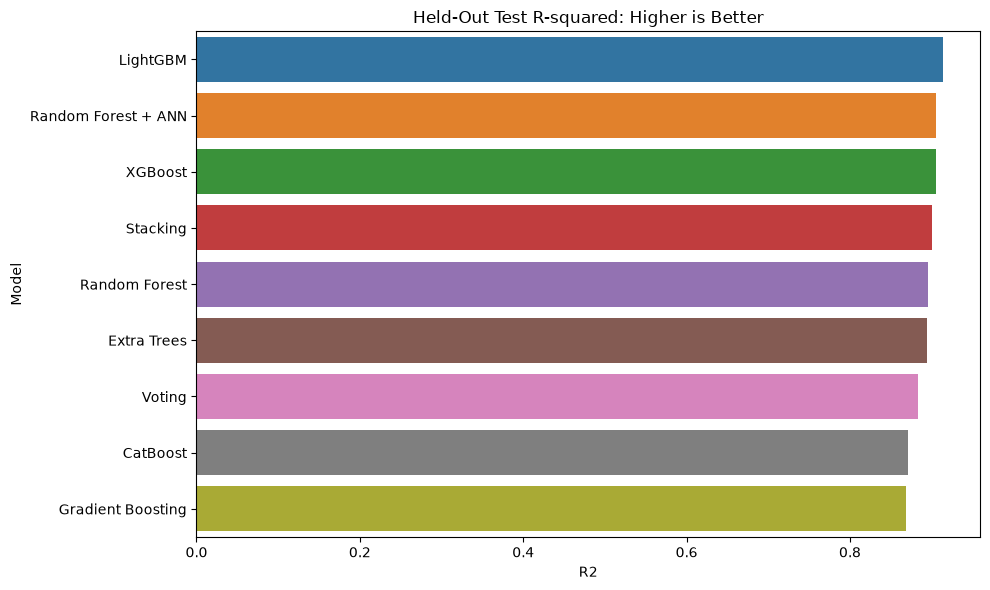

In [2]:
ensemble_sorted = ensemble.sort_values('CV MAE Lakhs')
plt.figure(figsize=(10, 6))
sns.barplot(data=ensemble_sorted, x='CV MAE Lakhs', y='Model', hue='Model', legend=False)
plt.title('3-Fold Cross-Validation MAE: Lower is Better')
plt.xlabel('Mean Absolute Error (Lakhs)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=ensemble.sort_values('R2', ascending=False), x='R2', y='Model', hue='Model', legend=False)
plt.title('Held-Out Test R-squared: Higher is Better')
plt.tight_layout()
plt.show()

## 2. Ensemble paradigms
- **Bagging:** Random Forest and Extra Trees reduce variance by averaging diverse trees.
- **Boosting:** Gradient Boosting, XGBoost, LightGBM, and CatBoost build sequential trees that correct earlier errors.
- **Stacking:** Ridge, random forest, and gradient boosting predictions are combined by a Ridge meta-learner.
- **Voting:** Diverse estimators contribute to a single averaged prediction.
- **Hybrid:** Random Forest plus an ANN are combined with stacking and a Ridge meta-learner.

In [3]:
selected = metadata['selected_model']
metrics = metadata['test_metrics']
print('Selected model:', selected)
print('Cross-validation MAE (Lakhs):', round(metadata['CV MAE Lakhs'], 3))
print('Held-out MAE (Lakhs):', round(metrics['MAE_Lakhs'], 3))
print('Held-out RMSE (Lakhs):', round(metrics['RMSE_Lakhs'], 3))
print('Held-out R-squared:', round(metrics['R2'], 3))

Selected model: Extra Trees
Cross-validation MAE (Lakhs): 5.304
Held-out MAE (Lakhs): 5.15
Held-out RMSE (Lakhs): 15.079
Held-out R-squared: 0.894


## 3. Hyperparameter tuning results
Random Forest, Gradient Boosting, and XGBoost were tuned using randomized cross-validation searches with 3-fold cross-validation. MAE is reported in Lakhs. Negative `mean_test_score` values are converted to positive MAE values (`CV MAE = -mean_test_score`).

Best tuned model summary


,Model,Training Time (s),CV MAE Lakhs,MAE_Lakhs,RMSE_Lakhs,R2,Best Parameters
0,XGBoost,1.351501,6.531787,6.562889,14.629561,0.900675,"{""model__colsample_bytree"": 0.7428600453765822..."
1,Gradient Boosting,5.230466,7.724427,8.038862,15.994555,0.881276,"{""model__learning_rate"": 0.06681790353582674, ..."
2,Random Forest,5.194550,10.528672,11.248932,24.406743,0.723552,"{""model__max_depth"": 29, ""model__max_features""..."


Complete 3-fold tuning candidates


,Model,CV MAE Lakhs,std_test_score,rank_test_score,params,split0_test_score,split1_test_score,split2_test_score,mean_fit_time,std_fit_time
5,Gradient Boosting,7.724427,0.054250,1,{'model__learning_rate': np.float64(0.06681790...,-7.743098,-7.779537,-7.650646,1.690211,0.286550
6,Gradient Boosting,10.278294,0.047058,2,{'model__learning_rate': np.float64(0.05045461...,-10.306198,-10.212020,-10.316665,1.206196,0.007673
7,Gradient Boosting,10.728938,0.086082,3,{'model__learning_rate': np.float64(0.07423304...,-10.753235,-10.820098,-10.613482,0.702886,0.004258
4,Gradient Boosting,11.959562,0.030403,4,{'model__learning_rate': np.float64(0.04253785...,-11.993353,-11.919641,-11.965694,0.532352,0.002928
3,Random Forest,10.528672,0.209567,1,"{'model__max_depth': 29, 'model__max_features'...",-10.430605,-10.335499,-10.819913,0.691474,0.127425
2,Random Forest,12.792121,0.221443,2,"{'model__max_depth': 18, 'model__max_features'...",-12.693150,-12.584294,-13.098918,0.970665,0.141700
0,Random Forest,13.446595,0.200144,3,"{'model__max_depth': 14, 'model__max_features'...",-13.463131,-13.193620,-13.683034,0.436417,0.058777
1,Random Forest,21.654211,0.218000,4,"{'model__max_depth': 14, 'model__max_features'...",-21.492265,-21.962375,-21.507993,0.595944,0.043119
10,XGBoost,6.531787,0.121376,1,{'model__colsample_bytree': np.float64(0.74286...,-6.471824,-6.422480,-6.701058,0.738199,0.026347
8,XGBoost,6.534061,0.143530,2,{'model__colsample_bytree': np.float64(0.81236...,-6.481090,-6.390851,-6.730243,0.621766,0.018501


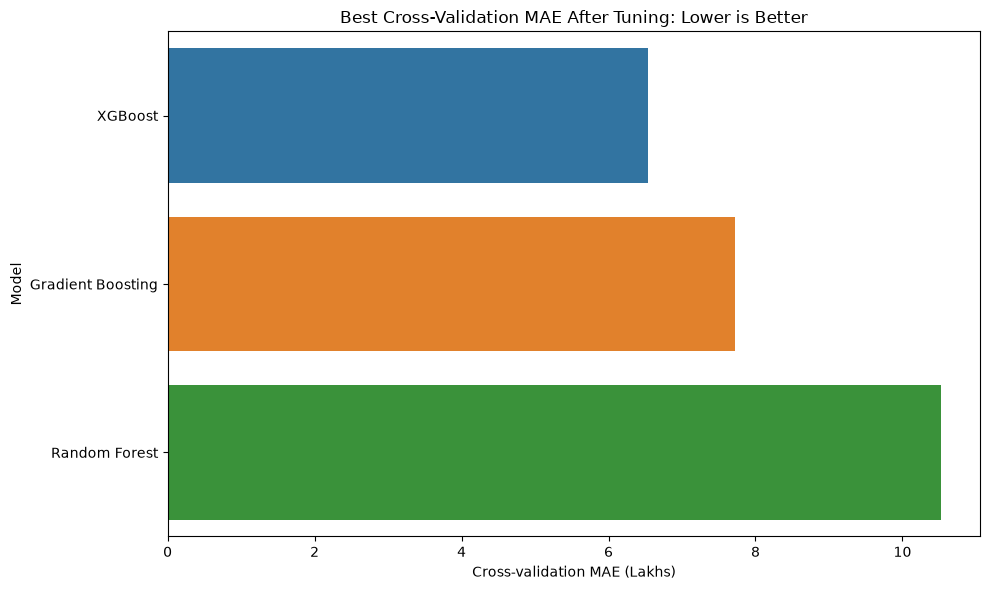

In [4]:
tuned = pd.read_csv(root / 'artifacts/tuned_results.csv')
tuning_cv = pd.read_csv(root / 'artifacts/tuning_cv_results.csv')

print('Best tuned model summary')
display(tuned)

print('Complete 3-fold tuning candidates')
tuning_display = tuning_cv.copy()
tuning_display['CV MAE Lakhs'] = -tuning_display['mean_test_score']
display_columns = [
    'Model', 'CV MAE Lakhs', 'std_test_score', 'rank_test_score',
    'params', 'split0_test_score', 'split1_test_score', 'split2_test_score',
    'mean_fit_time', 'std_fit_time'
]
display(tuning_display[display_columns].sort_values(['Model', 'rank_test_score']))

plt.figure(figsize=(10, 6))
sns.barplot(data=tuned.sort_values('CV MAE Lakhs'), x='CV MAE Lakhs', y='Model', hue='Model', legend=False)
plt.title('Best Cross-Validation MAE After Tuning: Lower is Better')
plt.xlabel('Cross-validation MAE (Lakhs)')
plt.tight_layout()
plt.show()

## 4. Tuning interpretation
The tuning table records every tested parameter combination, fold scores, score variability, fit time, and rank. Random Forest is tuned over depth, maximum features, leaf size, split size, and tree count. Gradient Boosting is tuned over depth, learning rate, iterations, and subsampling. XGBoost is additionally tuned over column subsampling.

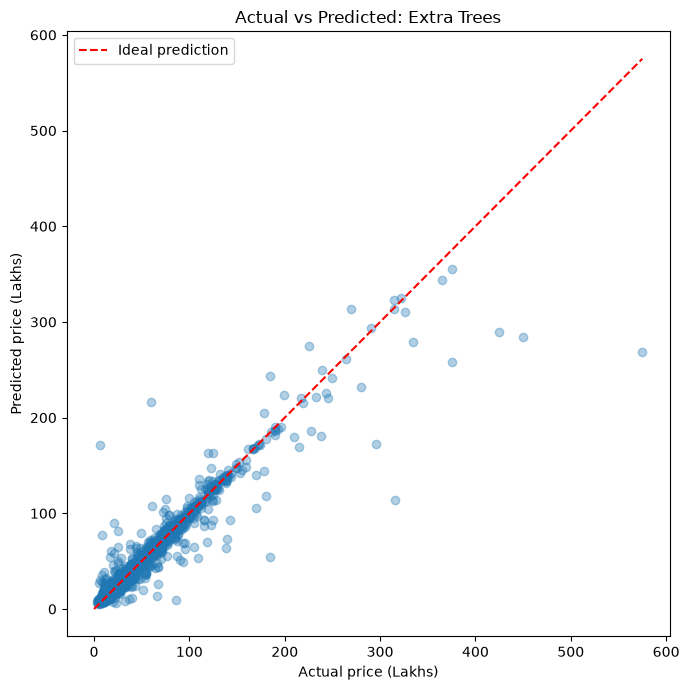

In [5]:
plt.figure(figsize=(7, 7))
plt.scatter(predictions['Actual Lakhs'], predictions['Predicted Lakhs'], alpha=0.35)
limit = max(predictions[['Actual Lakhs', 'Predicted Lakhs']].max())
plt.plot([0, limit], [0, limit], '--', color='red', label='Ideal prediction')
plt.xlabel('Actual price (Lakhs)')
plt.ylabel('Predicted price (Lakhs)')
plt.title(f'Actual vs Predicted: {selected}')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Interpretation and Limitations
The results show that tree-based ensemble methods perform well in predicting Sri Lankan used-vehicle prices. Extra Trees achieved the lowest cross-validation MAE (5.3038 Lakhs) and test MAE (5.1503 Lakhs), making it the preferred model for minimizing average prediction errors. However, LightGBM achieved the lowest RMSE (13.6485 Lakhs) and highest R² (0.9136), indicating better performance in reducing larger errors and explaining price variations. The RF+ANN hybrid and Stacking models did not outperform Extra Trees, suggesting that more complex ensemble approaches do not always improve prediction accuracy. MAE measures the average absolute error, while RMSE gives greater importance to larger prediction errors.

The main limitations include reliance on historical listing prices rather than actual selling prices, limited information about vehicle condition and maintenance history, and possible changes in Sri Lankan market conditions. Additionally, predictions for rare or unseen vehicle models may be less reliable, as the models learn from patterns in the available dataset. The evaluation is also limited to a single dataset, so performance on new market data may differ. Overall, the findings highlight the effectiveness of ensemble learning for vehicle price prediction while emphasizing the importance of model selection, data quality, and generalization.